# BOX, BOX: A Data-Driven Analysis of Formula 1 Race Performance
### 2026 British Grand Prix (race and qualifying)

**Data:** lap-by-lap timing files from the [TracingInsights](https://github.com/TracingInsights/2026) repository
(race and qualifying `session_laptimes.json`, race `drivers.json`).

**Three investigations**
1. **Driver performance** - which drivers had the strongest race pace? *(pandas, NumPy)*
2. **Tyres and strategy** - how do medium and hard tyres wear, and how did strategies differ? *(pandas, NumPy, SciPy)*
3. **Qualifying vs race** - did qualifying predict race performance? *(pandas, SciPy)*

The code lives in `src/`; this notebook calls it and tells the story.

In [2]:
import sys
from pathlib import Path

# make the project root importable whether the notebook runs from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src import data_cleaning as clean
from src import data_loader as loader
from src import driver_analysis as da
from src import tyre_analysis as ta
from src import visualisation as vis

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 1. Load and clean the data

In [3]:
raw_race = loader.load_raw_laps("race")
raw_quali = loader.load_raw_laps("qualifying")
print("Race:", raw_race.shape, "| Qualifying:", raw_quali.shape)
raw_race[["drv", "lap", "time", "compound", "pin", "pout", "status"]].head(8)

Race: (1115, 42) | Qualifying: (309, 43)


,drv,lap,time,compound,pin,pout,status
0,ALB,1,142.352,MEDIUM,3475.688,None,12
1,ALB,2,133.382,HARD,None,3519.933,12
2,ALB,3,95.816,HARD,None,None,1
3,ALB,4,96.46,HARD,None,None,1
4,ALB,5,96.299,HARD,None,None,1
5,ALB,6,98.07,HARD,None,None,1
6,ALB,7,105.128,HARD,None,None,1
7,ALB,8,97.882,HARD,None,None,1


**A data-quality trap:** a missing value is written as the *text* `"None"`, which pandas does not see as missing.
`clean_laps` turns it into a real `NaN`.

In [4]:
print("'None' texts in the raw race table:", int((raw_race == "None").sum().sum()))
race = clean.prepare_race_laps(raw_race)
quali = clean.prepare_qualifying_laps(raw_quali)
drivers = loader.load_drivers()
colors = vis.team_colors(drivers)
ranges = clean.neutralised_ranges(race)
print("Laps under safety car / VSC:", ranges)
print(f"Clean race laps: {race['is_clean'].sum()} of {len(race)} | valid qualifying laps: {quali['is_valid_lap'].sum()} of {len(quali)}")
loader.save_processed(race, "race_laps_clean")
loader.save_processed(quali, "qualifying_laps_clean")
race[["driver", "lap", "lap_time_s", "compound", "tyre_age", "neutralised", "is_clean", "fuel_corrected_s"]].head(8)

'None' texts in the raw race table: 3383
Laps under safety car / VSC: [('Safety car', 45, 52), ('VSC', 20, 22), ('VSC', 36, 39)]
Clean race laps: 786 of 1115 | valid qualifying laps: 97 of 309


,driver,lap,lap_time_s,compound,tyre_age,neutralised,is_clean,fuel_corrected_s
0,ALB,1,142.352,MEDIUM,1,False,False,139.409692
1,ALB,2,133.382,HARD,1,False,False,130.497385
2,ALB,3,95.816,HARD,2,False,True,92.989077
3,ALB,4,96.460,HARD,3,False,True,93.690769
4,ALB,5,96.299,HARD,4,False,True,93.587462
5,ALB,6,98.070,HARD,5,False,True,95.416154
6,ALB,7,105.128,HARD,6,False,True,102.531846
7,ALB,8,97.882,HARD,7,False,True,95.343538


## 2. Investigation 1 - Which drivers had the strongest race pace?

Only **clean laps** are used (no first lap, pit laps, yellow-flag, safety-car or VSC laps, nor restart laps) and lap times are
**fuel-corrected**. Consistency = standard deviation / mean (%).

In [5]:
classification = da.race_classification(race)
pace = da.race_pace_summary(race)
pace[["driver", "team", "clean_laps", "mean_lap_s", "median_lap_s", "fastest_lap_s",
      "std_fc_s", "consistency_pct", "gap_to_best_s", "pace_rank"]].round(3)

,driver,team,clean_laps,mean_lap_s,median_lap_s,fastest_lap_s,std_fc_s,consistency_pct,gap_to_best_s,pace_rank
0,LEC,Ferrari,38,93.789,93.850,92.871,0.471,0.511,0.000,1
1,ANT,Mercedes,33,94.050,94.066,91.777,0.469,0.508,0.075,2
2,VER,Red Bull Racing,37,94.099,94.143,92.101,0.425,0.460,0.255,3
3,RUS,Mercedes,36,94.051,94.483,92.489,0.571,0.618,0.276,4
4,HAM,Ferrari,38,94.097,94.222,92.309,0.669,0.724,0.357,5
5,NOR,McLaren,37,94.359,94.722,92.625,0.408,0.440,0.511,6
6,HAD,Red Bull Racing,36,94.565,94.802,92.268,0.543,0.585,0.860,7
7,PIA,McLaren,36,94.954,94.993,92.917,0.951,1.019,0.906,8
8,LAW,Racing Bulls,37,95.156,95.635,93.648,0.444,0.475,1.311,9
9,LIN,Racing Bulls,36,95.142,95.582,93.632,0.494,0.528,1.387,10


In [6]:
best = pace.iloc[0]
fastest = pace.loc[pace["fastest_lap_s"].idxmin()]
steadiest = pace.loc[pace["consistency_pct"].idxmin()]
print(f"Best median race pace: {best['driver']} | fastest single lap: {fastest['driver']} ({fastest['fastest_lap_s']:.3f} s, pace rank {fastest['pace_rank']})")
print(f"Most consistent: {steadiest['driver']} ({steadiest['consistency_pct']:.2f}%)")
clean_laps = race[race["is_clean"]]
print(f"Average lap-time std: {clean_laps.groupby('driver')['lap_time_s'].std().mean():.2f} s raw "
      f"vs {clean_laps.groupby('driver')['fuel_corrected_s'].std().mean():.2f} s fuel-corrected")

Best median race pace: LEC | fastest single lap: ANT (91.777 s, pace rank 2)
Most consistent: NOR (0.44%)
Average lap-time std: 0.93 s raw vs 0.66 s fuel-corrected


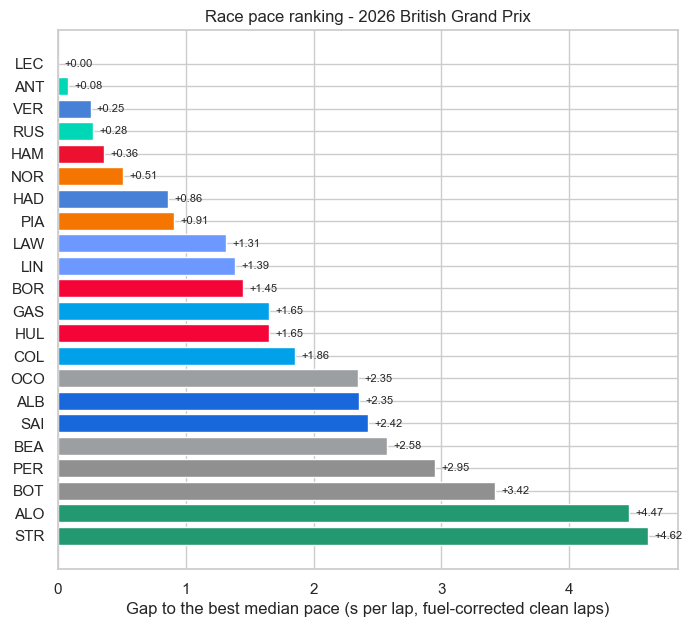

In [7]:
vis.plot_pace_ranking(pace, colors, save_as="1_pace_ranking.png")
plt.show()

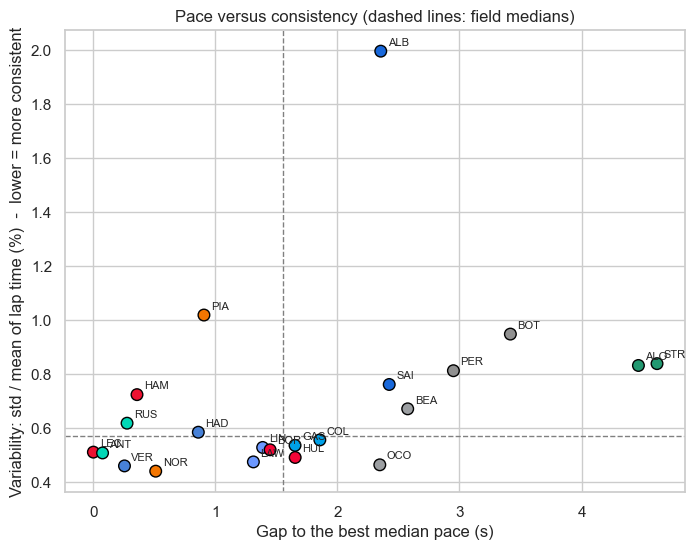

In [8]:
vis.plot_pace_vs_consistency(pace, colors, save_as="2_pace_vs_consistency.png")
plt.show()

**Your findings for Investigation 1** *(3-4 sentences in your own words: who was fastest, whether the fastest lap matches the
best race pace, who was most consistent, and what limits the comparison, e.g. drivers with few clean laps).*

## 3. Investigation 2 - Tyres and strategy

For every stint, a line of fuel-corrected lap time against tyre age is fitted with `scipy.stats.linregress`; the slope is the
time lost per extra lap of tyre age.

In [9]:
stints = ta.stints_table(race)
print(stints.groupby("compound").agg(stints=("stint", "count"), mean_length=("n_laps", "mean")).round(1))
ta.strategy_summary(race)

          stints  mean_length
compound                     
HARD          22         20.8
MEDIUM        30         18.4
SOFT          21          5.0


,driver,team,stops,strategy,sc_stops,laps_completed,last_position
0,LEC,Ferrari,2,M-H-S,1,52,1.0
1,RUS,Mercedes,2,M-H-M,0,52,2.0
2,HAM,Ferrari,2,M-H-S,1,52,3.0
3,NOR,McLaren,3,M-H-M-S,2,52,4.0
4,HAD,Red Bull Racing,3,M-H-M-S,2,52,5.0
5,LAW,Racing Bulls,2,M-H-S,1,52,6.0
6,LIN,Racing Bulls,2,M-H-S,1,52,7.0
7,BOR,Audi,2,M-H-S,1,52,8.0
8,ANT,Mercedes,3,M-H-M-M,0,52,9.0
9,COL,Alpine,2,M-H-S,2,52,10.0


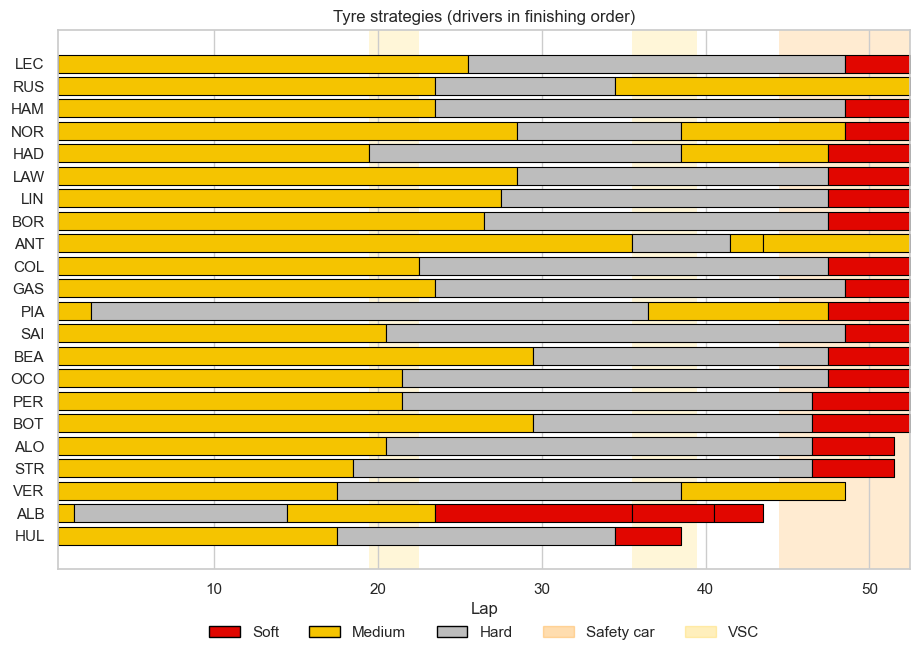

In [10]:
vis.plot_strategy(stints, classification["driver"].tolist(), ranges, save_as="3_strategy.png")
plt.show()

In [11]:
deg = ta.degradation(race, min_laps=6)
print(f"{len(deg)} of {len(stints)} stints are long enough to fit")
ta.degradation_by_compound(deg).round(4)

47 of 73 stints are long enough to fit


,compound,n_stints,median_slope,mean_slope,std_slope,p_value_vs_zero
0,SOFT,1,0.1835,0.1835,NaN,NaN
1,MEDIUM,25,0.0483,0.0514,0.0373,0.0
2,HARD,21,0.0577,0.0835,0.0746,0.0


Medium vs hard degradation: no significant difference (Mann-Whitney p = 0.128)


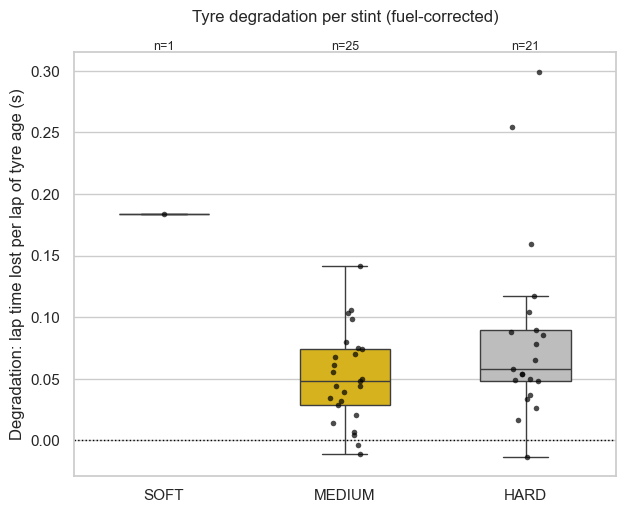

In [12]:
result = ta.compare_compounds(deg, "MEDIUM", "HARD")
verdict = "no significant difference" if result["p_value"] > 0.05 else "a significant difference"
print(f"Medium vs hard degradation: {verdict} (Mann-Whitney p = {result['p_value']:.3f})")
vis.plot_degradation(deg, save_as="4_degradation.png")
plt.show()

### Case study: the pole-sitter's race

      condition  n_stops  median_s  mean_s  fastest_s
0    Green flag       24     29.98   32.75      28.39
1  Under SC/VSC       27     29.51   30.94      28.60

ANT pit stops:
 lap  duration_s  under_neutralised
  35        28.8              False
  41        41.4              False
  43        33.8              False


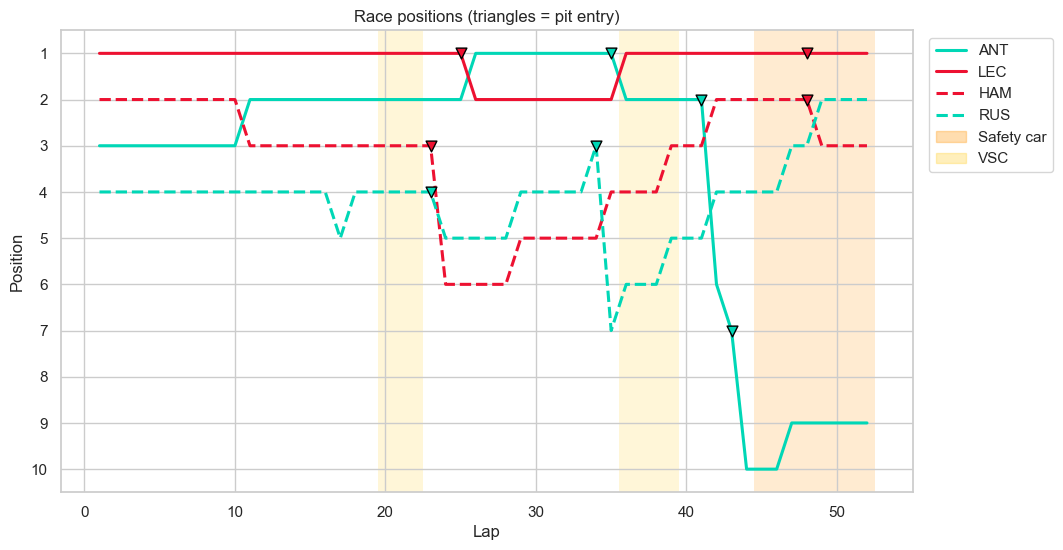

In [13]:
pit_times = ta.pit_lane_times(race)
print(ta.pit_lane_summary(pit_times).round(2))
print()
print("ANT pit stops:")
print(pit_times[pit_times["driver"] == "ANT"][["lap", "duration_s", "under_neutralised"]].round(1).to_string(index=False))
vis.plot_position_trace(race, ["ANT", "LEC", "HAM", "RUS"], colors, ranges, save_as="5_position_trace.png")
plt.show()

**Your findings for Investigation 2** *(medium vs hard wear, why soft tyres appear only in short stints, what the safety car did to
the strategies, and the limits: few soft stints, approximate fuel correction, track evolution, no cause given for slow stops).*

## 4. Investigation 3 - Did qualifying predict the race?

Qualifying order follows the Q1/Q2/Q3 knockout rules (deleted laps ignored). It is the qualifying order, **not** the starting grid
(penalties are not in the data). Race pace is ranked on fuel-corrected clean laps.

In [14]:
quali_table = da.qualifying_classification(quali)
table = da.qualifying_vs_race(quali_table, pace, classification)
corr = da.quali_race_correlation(table)
print(f"Spearman rho (qualifying position vs race-pace rank): {corr['spearman_rho']:.2f} (p = {corr['spearman_p']:.1e})")
up = table.loc[table["rank_difference"].idxmax()]
down = table.loc[table["rank_difference"].idxmin()]
print(f"Race pace most above qualifying position: {up['driver']} (+{up['rank_difference']:.0f}); most below: {down['driver']} ({down['rank_difference']:.0f})")
table.round(2)

Spearman rho (qualifying position vs race-pace rank): 0.95 (p = 8.5e-12)
Race pace most above qualifying position: COL (+5); most below: BEA (-4)


,driver,team,qualifying_position,gap_to_pole_pct,pace_rank,race_gap_pct,rank_difference,last_position,classified,positions_gained
0,ANT,Mercedes,1,0.00,2,0.08,-1,9.0,True,-8.0
1,LEC,Ferrari,2,0.20,1,0.00,1,1.0,True,1.0
2,HAM,Ferrari,3,0.39,5,0.39,-2,3.0,True,0.0
3,RUS,Mercedes,4,0.42,4,0.30,0,2.0,True,2.0
4,HAD,Red Bull Racing,5,0.72,7,0.93,-2,5.0,True,0.0
5,NOR,McLaren,6,0.87,6,0.55,0,4.0,True,2.0
6,VER,Red Bull Racing,7,0.89,3,0.28,4,3.0,True,4.0
7,PIA,McLaren,8,1.05,8,0.98,0,12.0,True,-4.0
8,LIN,Racing Bulls,9,1.36,10,1.50,-1,7.0,True,2.0
9,LAW,Racing Bulls,10,1.35,9,1.42,1,6.0,True,4.0


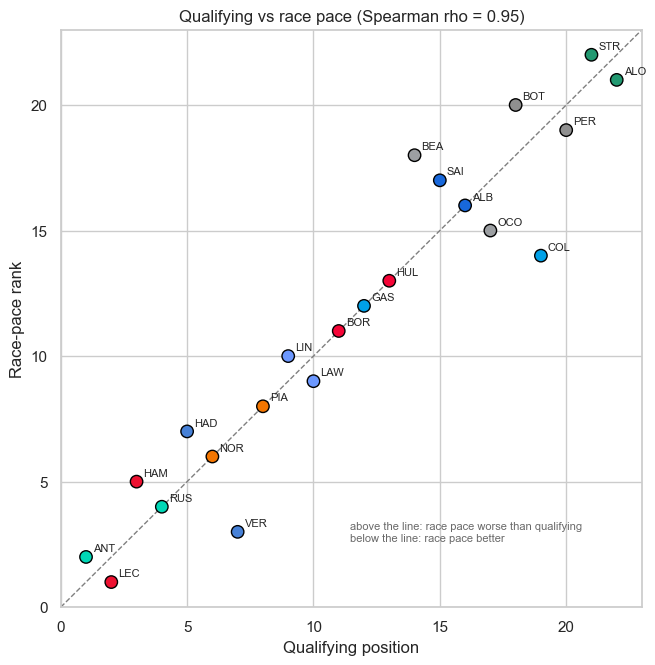

In [15]:
vis.plot_quali_vs_race(table, corr, colors, save_as="6_quali_vs_race.png")
plt.show()

**Your findings for Investigation 3** *(how strong the correlation is, who over- and under-performed, and why positions gained is not
the same as pace, e.g. strategy, safety car, retirements).*

In [16]:
loader.save_processed(pace, "race_pace_summary")
loader.save_processed(table, "qualifying_vs_race")
print("Saved the result tables to data/processed/")

Saved the result tables to data/processed/


## 5. Conclusions and limitations

*Write your overall conclusions here (one short paragraph per investigation).*

**Limitations to mention**
- One race only: the results describe the 2026 British Grand Prix, not a season.
- Fuel correction uses an assumed 100 kg start load and 0.03 s per kg.
- Soft tyres appear only in short end-of-race stints, so their degradation cannot be estimated.
- Track evolution and traffic add noise to the degradation slopes.
- Qualifying order, not the starting grid; knocked-out drivers set their times on a slower track.
- The data shows *what* happened, not *why* (slow stops, retirements).